# Word Embeddings: Word2Vec, FastText, Doc2Vec, and Clustering
### Introduction to Large Language Models — Assignment 5

This notebook reuses the **same 1,000,000-sentence training corpus and train/dev/test splits**
built in Assignment 3 (loaded from `lab3_data/{LANGUAGE}_train_pool.parquet`, `_dev.parquet`,
`_test.parquet`). We use **Gensim** (not a from-scratch implementation this time — the
assignment explicitly points at Gensim's own tutorials) to:

1. Train **Word2Vec**, **FastText**, and **Doc2Vec** models on the training data, following the
   parameter conventions from Gensim's own tutorials:
   - Word2Vec: <https://radimrehurek.com/gensim/auto_examples/tutorials/run_word2vec.html>
   - FastText: <https://radimrehurek.com/gensim/auto_examples/tutorials/run_fasttext.html>
   - Doc2Vec: <https://radimrehurek.com/gensim/auto_examples/tutorials/run_doc2vec_lee.html>
2. **K-means cluster** the trained word vectors, and represent each cluster by its 20 words
   closest to the cluster centroid.
3. Represent every dev/test sentence as a vector two ways — averaged word embeddings, and
   inferred Doc2Vec embeddings — and for each one, find its **closest sentence** (by cosine
   similarity, searched against every training sentence's vector under the same representation).

**What we borrow from each tutorial, specifically:**
- From the Word2Vec tutorial: the `Word2Vec(sentences=..., vector_size=..., window=..., min_count=..., workers=...)`
  constructor pattern (their `MyCorpus` streaming-iterator idea is mirrored in §2 below, since our
  corpus is much larger than fits comfortably as a single Python list — 1,000,000 sentences).
- From the FastText tutorial: the extra `min_n`/`max_n` character-n-gram parameters, and the
  fact that `wv[word]` works even for out-of-vocabulary words (via subword hashing) — this is
  why FastText, unlike Word2Vec, never needs to skip a word when building a sentence vector.
- From the Doc2Vec tutorial: `TaggedDocument(words, [tag])` for training data, `model.dv[tag]`
  to look up a **training** document's vector directly (no re-inference needed, exactly as the
  tutorial does when checking self-similarity), and `model.infer_vector(tokens)` for **new**
  (dev/test) text.


## 0. Setup

In [1]:
%pip install -q gensim scikit-learn pandas pyarrow numpy regex tqdm matplotlib


Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import time
import pickle
import logging
from collections import Counter

import numpy as np
import pandas as pd
import regex
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import gensim
from gensim.models import Word2Vec
from gensim.models.fasttext import FastText
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn.cluster import KMeans

# Gensim tutorials enable INFO-level logging to show training progress; we mirror that but
# cap it at WARNING by default so a 1,000,000-sentence run doesn't flood the notebook -- flip
# to logging.INFO if you want the full per-epoch training log like the tutorials show.
logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s', level=logging.WARNING)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

LANGUAGE = "guj_Gujr"     # must match the LANGUAGE used in the Assignment 3 notebook
LAB3_DATA_DIR = "/Users/vatsalbateriwala/Developer/sem 7/ILLM Lab/Lab-3/lab3_data"
ARTIFACTS_DIR = "lab5_artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

VECTOR_SIZE = 100          # embedding dimensionality for all three models
WINDOW = 5
MIN_COUNT = 5
WORKERS = 4
W2V_EPOCHS = 5             # gensim default
FASTTEXT_EPOCHS = 5
DOC2VEC_EPOCHS = 20
N_CLUSTERS = 50
WORDS_PER_CLUSTER = 20

# QUICK_TEST trains on a small subset first, so you can sanity-check the whole notebook (all
# three models + clustering + nearest-sentence search) in a couple of minutes before committing
# to the full 1,000,000-sentence run, which is legitimately slow for Doc2Vec in particular.
QUICK_TEST = False
MAX_TRAIN_SENTENCES = 1_000_000
if QUICK_TEST:
    MAX_TRAIN_SENTENCES = 20_000
    N_CLUSTERS = 15
    DOC2VEC_EPOCHS = 10

print(f"Language: {LANGUAGE}   QUICK_TEST={QUICK_TEST}   MAX_TRAIN_SENTENCES={MAX_TRAIN_SENTENCES:,}")


Language: guj_Gujr   QUICK_TEST=False   MAX_TRAIN_SENTENCES=1,000,000


## 1. Load the Assignment 3 corpus & splits

Reuses `lab3_data/{LANGUAGE}_train_pool.parquet`, `_dev.parquet`, `_test.parquet` exactly as
written by the Assignment 3 notebook (run that notebook first, through §3, if these aren't
present). "Validation set" in this assignment is the `dev` split from Assignment 3.


In [4]:
def _load(name):
    path = os.path.join(LAB3_DATA_DIR, f"{LANGUAGE}_{name}.parquet")
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Couldn't find {path}. Run the Assignment 3 notebook first (through \u00a73, "
            f"'Length-stratified train/dev/test split') so it writes "
            f"{LANGUAGE}_train_pool.parquet, {LANGUAGE}_dev.parquet, and {LANGUAGE}_test.parquet "
            f"into {LAB3_DATA_DIR}/."
        )
    return pd.read_parquet(path)

train_pool_df = _load("train_pool")
val_df = _load("dev")     # "validation set" in this assignment == the dev split from Assignment 3
test_df = _load("test")

n_train = min(MAX_TRAIN_SENTENCES, len(train_pool_df))
if n_train < MAX_TRAIN_SENTENCES:
    print(f"WARNING: only {len(train_pool_df):,} training sentences available "
          f"(requested {MAX_TRAIN_SENTENCES:,}); using all of them.")

train_sentences_text = train_pool_df["text"].tolist()[:n_train]
val_sentences_text = val_df["text"].tolist()
test_sentences_text = test_df["text"].tolist()

print(f"train: {len(train_sentences_text):,}   val: {len(val_sentences_text)}   test: {len(test_sentences_text)}")


train: 1,000,000   val: 1000   test: 1000


## 2. Tokenize

Same Unicode-aware word tokenizer used throughout this course. Following the spirit of the
Word2Vec tutorial's `MyCorpus` memory-friendly iterator (our corpus is far bigger than the
tutorial's toy example, so we tokenize once up front and keep the token lists — at 1,000,000
sentences this comfortably fits in memory, unlike, say, a 100M+ sentence corpus where a
streaming iterator would be worth the extra complexity).


In [5]:
_WORD_RE = regex.compile(r"[\p{L}\p{M}]+|\p{N}+", regex.UNICODE)

def word_tokenize(sentence):
    return _WORD_RE.findall(sentence)

train_tokenized = [word_tokenize(s) for s in tqdm(train_sentences_text, desc="tokenizing train")]
val_tokenized = [word_tokenize(s) for s in val_sentences_text]
test_tokenized = [word_tokenize(s) for s in test_sentences_text]

print(f"train tokens: {sum(len(s) for s in train_tokenized):,} across {len(train_tokenized):,} sentences")


tokenizing train: 100%|██████████| 1000000/1000000 [00:03<00:00, 274472.91it/s]


train tokens: 14,010,994 across 1,000,000 sentences


## 3a. Train Word2Vec

Directly follows the tutorial's "Training Your Own Model" section:
`Word2Vec(sentences=..., vector_size=..., window=..., min_count=..., workers=...)` builds the
vocabulary and trains in one call. `model.wv` holds the word vectors, exactly as in the tutorial
(`vec_king = model.wv['king']`).


In [6]:
t0 = time.time()
w2v_model = Word2Vec(
    sentences=train_tokenized,
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=WORKERS,
    epochs=W2V_EPOCHS,
    seed=RANDOM_SEED,
)
print(f"Word2Vec trained in {time.time() - t0:.1f}s, vocab size = {len(w2v_model.wv.index_to_key):,}")

# quick sanity check, same operation the tutorial demonstrates
sample_word = w2v_model.wv.index_to_key[0]
print(f"Most similar to {sample_word!r}: {w2v_model.wv.most_similar(sample_word, topn=5)}")


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Word2Vec trained in 21.2s, vocab size = 107,441
Most similar to 'છે': [('તે', 0.5450730919837952), ('નથી', 0.5311013460159302), ('છેઃ', 0.5174371600151062), ('પણ', 0.49914753437042236), ('અન્યને', 0.46911874413490295)]


## 3b. Train FastText

Same parameters as Word2Vec, plus FastText's own `min_n`/`max_n` (character n-gram range used
to build subword vectors — this is what lets FastText handle out-of-vocabulary words, per the
tutorial's "fastText attempts to solve this by treating each word as the aggregation of its
subwords" explanation).


In [7]:
t0 = time.time()
ft_model = FastText(
    sentences=train_tokenized,
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=WORKERS,
    epochs=FASTTEXT_EPOCHS,
    min_n=3,
    max_n=6,
    seed=RANDOM_SEED,
)
print(f"FastText trained in {time.time() - t0:.1f}s, vocab size = {len(ft_model.wv.index_to_key):,}")

# demonstrate OOV handling (the key FastText feature per the tutorial): make up a word that's
# very unlikely to be in the training vocabulary and confirm FastText still returns a vector.
made_up_word = ft_model.wv.index_to_key[0] + ft_model.wv.index_to_key[1][:2]
in_vocab = made_up_word in ft_model.wv.key_to_index
print(f"{made_up_word!r} in vocabulary: {in_vocab}  (FastText can still embed it via subwords: "
      f"vector norm = {np.linalg.norm(ft_model.wv[made_up_word]):.3f})")


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


FastText trained in 70.3s, vocab size = 107,441
'છેઅન' in vocabulary: False  (FastText can still embed it via subwords: vector norm = 5.277)


## 3c. Train Doc2Vec

Follows the tutorial exactly: wrap every training sentence in a `TaggedDocument` with its
(zero-based) index as the tag, then `build_vocab` + `train`.


In [8]:
train_tagged = [TaggedDocument(words=tokens, tags=[i]) for i, tokens in enumerate(train_tokenized)]

t0 = time.time()
d2v_model = Doc2Vec(
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=WORKERS,
    epochs=DOC2VEC_EPOCHS,
    seed=RANDOM_SEED,
)
d2v_model.build_vocab(train_tagged)
d2v_model.train(train_tagged, total_examples=d2v_model.corpus_count, epochs=d2v_model.epochs)
print(f"Doc2Vec trained in {time.time() - t0:.1f}s, vocab size = {len(d2v_model.wv.index_to_key):,}, "
      f"{len(d2v_model.dv)} document vectors")


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Doc2Vec trained in 2661.7s, vocab size = 107,441, 1000000 document vectors


In [9]:
# save all three models (per each tutorial's "Storing and loading models" section)
w2v_model.save(os.path.join(ARTIFACTS_DIR, "word2vec.model"))
ft_model.save(os.path.join(ARTIFACTS_DIR, "fasttext.model"))
d2v_model.save(os.path.join(ARTIFACTS_DIR, "doc2vec.model"))
print("Saved all three trained models to", ARTIFACTS_DIR)


Saved all three trained models to lab5_artifacts


## 4. K-means clustering of words

Cluster the **Word2Vec** word vectors with K-means (`N_CLUSTERS` clusters), then for each
cluster, report the 20 words whose vectors are closest (Euclidean distance) to that cluster's
centroid — this is the standard way to give a human-readable "label" to an otherwise opaque
cluster of vectors.


In [10]:
words = w2v_model.wv.index_to_key
word_vectors = np.array([w2v_model.wv[w] for w in words], dtype=np.float32)
print(f"clustering {len(words):,} words into {N_CLUSTERS} clusters")

t0 = time.time()
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED, n_init=10)
cluster_labels = kmeans.fit_predict(word_vectors)
print(f"K-means fit in {time.time() - t0:.1f}s")

cluster_top_words = {}
for c in range(N_CLUSTERS):
    idx = np.where(cluster_labels == c)[0]
    if len(idx) == 0:
        cluster_top_words[c] = []
        continue
    centroid = kmeans.cluster_centers_[c]
    dists = np.linalg.norm(word_vectors[idx] - centroid, axis=1)
    order = np.argsort(dists)[:WORDS_PER_CLUSTER]
    cluster_top_words[c] = [words[idx[i]] for i in order]

for c in range(min(N_CLUSTERS, 10)):
    print(f"cluster {c:2d} ({(cluster_labels == c).sum():4d} words): {cluster_top_words[c]}")


clustering 107,441 words into 50 clusters
K-means fit in 29.8s
cluster  0 (2040 words): ['રાજકોટનાં', 'કાનાબાર', 'કટારા', 'સોજીત્રા', 'માવજી', 'માંડવીના', 'જીતેન્દ્રભાઈ', 'મેઘપર', 'વરતેજ', 'પાંભર', 'ચુડા', 'જેઠાભાઇ', 'નવાપુરા', 'પેથાપુર', 'ગારિયાધાર', 'વાલજીભાઈ', 'ભાટી', 'સાંસદશ્રી', 'જીવરાજ', 'થાનગઢ']
cluster  1 (1452 words): ['ઉપરાછાપરી', 'ચપ્પુના', 'કારચાલકે', 'મારેલ', 'કુહાડીના', 'ઘટનાસ્થળેથી', 'આધેડને', 'છરીની', 'બળજબરીપૂર્વક', 'ચપ્પાના', 'આંતરીને', 'ઝાડીમાં', 'ઢોરમાર', 'કોથળામાં', 'હવસખોર', 'વૃદ્ધને', 'પત્નિએ', 'બુટલેગરને', 'શખ્સના', 'રહેંસી']
cluster  2 ( 315 words): ['સાઈડમાં', 'રીક્ષામાં', 'ડમ્પર', 'રિક્ષામાં', 'ટ્રકમાં', 'જીપ', 'ટ્રકે', 'ખાડામાં', 'એક્ટિવા', 'થાંભલા', 'ટ્રેકટર', 'કારે', 'સાઇકલ', 'નાળા', 'મકાનના', 'પાઈપ', 'બોલેરો', 'મોટરસાયકલ', 'ઉભેલા', 'પલ્ટી']
cluster  3 ( 487 words): ['સરેન્ડર', 'પુનર્જીવિત', 'સિધ્ધ', 'તબદીલ', 'એન્ટર', 'ચરિતાર્થ', 'ટોર્ચર', 'બરતરફ', 'ભેગુ', 'પ્રોત્સાહીત', 'હોલ્ડ', 'રિપ્લેસ', 'પીછેહઠ', 'અનાદર', 'પરાસ્ત', 'પ્રકટ', 'સ્વિકાર', 'ઉશ્કેરણી', 'પ્રે

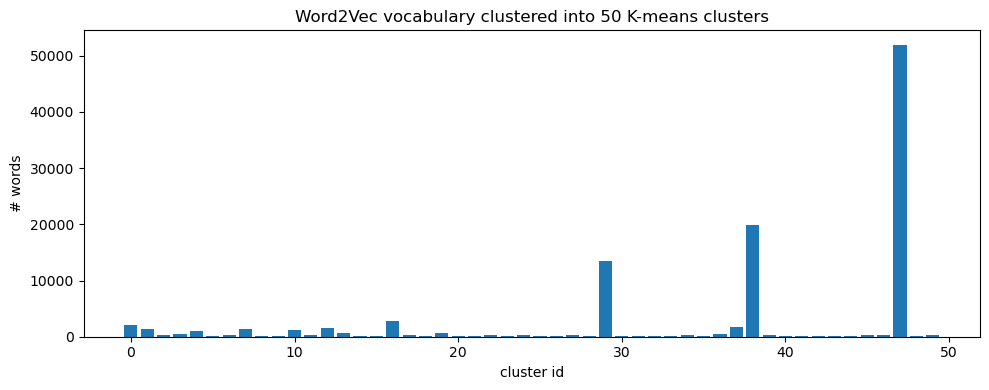

In [11]:
cluster_sizes = pd.Series(Counter(cluster_labels)).sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(cluster_sizes.index, cluster_sizes.values)
ax.set_xlabel("cluster id"); ax.set_ylabel("# words")
ax.set_title(f"Word2Vec vocabulary clustered into {N_CLUSTERS} K-means clusters")
plt.tight_layout()
plt.show()


## 5. Sentence representations for validation/test

Two ways to turn a sentence into a vector:

1. **Averaged word embeddings** — mean of each token's vector. We do this separately for
   Word2Vec (skipping any OOV token — Word2Vec simply has no vector for it) and FastText
   (never skips anything, since FastText can embed any token via subwords, per §3b).
2. **Doc2Vec embeddings** — `model.infer_vector(tokens)` for dev/test sentences (new, unseen
   text), vs. the directly-trained `model.dv[i]` for training sentences (no inference needed,
   exactly as the tutorial's self-similarity check does).


In [12]:
def sentence_vec_avg(tokens, wv):
    vecs = [wv[t] for t in tokens if t in wv]
    if not vecs:
        return np.zeros(wv.vector_size, dtype=np.float32)
    return np.mean(vecs, axis=0).astype(np.float32)

def sentence_vec_avg_fasttext(tokens, wv):
    # FastText can embed every token (even OOV) via subwords, so nothing is ever skipped --
    # only guard against a completely empty token list.
    if not tokens:
        return np.zeros(wv.vector_size, dtype=np.float32)
    vecs = [wv[t] for t in tokens]
    return np.mean(vecs, axis=0).astype(np.float32)


def build_all_vectors(tokenized_sentences, desc):
    n = len(tokenized_sentences)
    w2v_vecs = np.zeros((n, VECTOR_SIZE), dtype=np.float32)
    ft_vecs = np.zeros((n, VECTOR_SIZE), dtype=np.float32)
    for i, tokens in enumerate(tqdm(tokenized_sentences, desc=f"{desc}: word/fastText vectors")):
        w2v_vecs[i] = sentence_vec_avg(tokens, w2v_model.wv)
        ft_vecs[i] = sentence_vec_avg_fasttext(tokens, ft_model.wv)
    return w2v_vecs, ft_vecs


# training sentence vectors: word2vec/fastText need computing; Doc2Vec's are already trained
# (model.dv[i]) -- no re-inference needed, per the tutorial.
train_w2v_vecs, train_ft_vecs = build_all_vectors(train_tokenized, "train")
train_d2v_vecs = np.array([d2v_model.dv[i] for i in range(len(train_tokenized))], dtype=np.float32)

# validation/test vectors: word2vec/fastText as above; Doc2Vec via infer_vector (new text).
val_w2v_vecs, val_ft_vecs = build_all_vectors(val_tokenized, "val")
test_w2v_vecs, test_ft_vecs = build_all_vectors(test_tokenized, "test")

val_d2v_vecs = np.array([d2v_model.infer_vector(t) for t in tqdm(val_tokenized, desc="val: Doc2Vec infer_vector")], dtype=np.float32)
test_d2v_vecs = np.array([d2v_model.infer_vector(t) for t in tqdm(test_tokenized, desc="test: Doc2Vec infer_vector")], dtype=np.float32)

print("shapes:", train_w2v_vecs.shape, train_ft_vecs.shape, train_d2v_vecs.shape)


test: Doc2Vec infer_vector: 100%|██████████| 1000/1000 [00:00<00:00, 2244.91it/s]

shapes: (1000000, 100) (1000000, 100) (1000000, 100)


## 6. Closest training sentence for every validation/test sentence

For each representation (Word2Vec-avg, FastText-avg, Doc2Vec), find the training sentence with
the highest cosine similarity to each validation/test sentence. Cosine similarity between an
L2-normalized query matrix and an L2-normalized training matrix is just a single matrix
multiplication — this brute-force approach is exact (no approximation) and, done as one batched
`@` call rather than a Python loop, comfortably handles matching thousands of queries against a
training set of up to a million vectors.


In [13]:
def l2_normalize(X, eps=1e-8):
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    norms[norms < eps] = eps
    return X / norms

def find_nearest(query_vecs, train_vecs, batch_size=500):
    """Returns (nearest_idx, nearest_sim) for every row of query_vecs, searched against every
    row of train_vecs. Batches the query side to bound peak memory (batch_size x n_train
    similarity matrix at a time) while still using one BLAS matmul call per batch."""
    train_n = l2_normalize(train_vecs)
    query_n = l2_normalize(query_vecs)
    n = query_n.shape[0]
    nearest_idx = np.zeros(n, dtype=np.int64)
    nearest_sim = np.zeros(n, dtype=np.float32)
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        sim = query_n[start:end] @ train_n.T          # (batch, n_train)
        idx = np.argmax(sim, axis=1)
        nearest_idx[start:end] = idx
        nearest_sim[start:end] = sim[np.arange(end - start), idx]
    return nearest_idx, nearest_sim


results = {}
for split_name, w2v_vecs, ft_vecs, d2v_vecs, sentences in [
    ("val", val_w2v_vecs, val_ft_vecs, val_d2v_vecs, val_sentences_text),
    ("test", test_w2v_vecs, test_ft_vecs, test_d2v_vecs, test_sentences_text),
]:
    for method_name, q_vecs, t_vecs in [
        ("Word2Vec-avg", w2v_vecs, train_w2v_vecs),
        ("FastText-avg", ft_vecs, train_ft_vecs),
        ("Doc2Vec", d2v_vecs, train_d2v_vecs),
    ]:
        t0 = time.time()
        idx, sim = find_nearest(q_vecs, t_vecs)
        dt = time.time() - t0
        results[(split_name, method_name)] = (idx, sim)
        print(f"{split_name:5s} / {method_name:14s}: matched {len(idx)} sentences in {dt:.1f}s, "
              f"mean similarity to nearest = {sim.mean():.3f}")


val   / Word2Vec-avg  : matched 1000 sentences in 5.0s, mean similarity to nearest = 0.870
val   / FastText-avg  : matched 1000 sentences in 3.2s, mean similarity to nearest = 0.916
val   / Doc2Vec       : matched 1000 sentences in 3.1s, mean similarity to nearest = 0.676
test  / Word2Vec-avg  : matched 1000 sentences in 2.3s, mean similarity to nearest = 0.874
test  / FastText-avg  : matched 1000 sentences in 2.4s, mean similarity to nearest = 0.917
test  / Doc2Vec       : matched 1000 sentences in 3.3s, mean similarity to nearest = 0.682


In [14]:
# a few qualitative examples: validation sentences and their nearest training sentence,
# under each representation
for i in range(3):
    print(f"\nVAL[{i}]: {val_sentences_text[i]}")
    for method_name in ["Word2Vec-avg", "FastText-avg", "Doc2Vec"]:
        idx, sim = results[("val", method_name)]
        print(f"  {method_name:14s} -> train[{idx[i]}] (sim={sim[i]:.3f}): {train_sentences_text[idx[i]]}")



VAL[0]: મહેશભાઇ વાટલીયા, ડો.
  Word2Vec-avg   -> train[998287] (sim=0.992): બારૈયા, ડો.
  FastText-avg   -> train[98311] (sim=0.990): ચિરાગભાઇ પાનસુરીયા, ડો.
  Doc2Vec        -> train[41637] (sim=0.607): પ્રકાશ મોઢા, ડો.

VAL[1]: અને જે જીપની વાત છે.
  Word2Vec-avg   -> train[785728] (sim=0.971): જે ગૌરવપૂર્ણ વાત છે.
  FastText-avg   -> train[946845] (sim=0.969): જે ખુશીની વાત છે.
  Doc2Vec        -> train[707927] (sim=0.742): જો કે પોલીસના નામે તોડની વાત જે.

VAL[2]: ૧૨ ડોલર ઘટીને ૧૮.
  Word2Vec-avg   -> train[665309] (sim=0.954): ૫૦ ડોલર ઘટીને ૧,૭૯૮.
  FastText-avg   -> train[329836] (sim=0.961): ૫૨%) ઘટીને ૧૨,૧૦૬.
  Doc2Vec        -> train[179820] (sim=0.826): ૭ ટકાનો ઘટાડો દર્શાવે છે.


## 7. Save results

In [15]:
nearest_records = []
for split_name in ["val", "test"]:
    sentences = val_sentences_text if split_name == "val" else test_sentences_text
    for method_name in ["Word2Vec-avg", "FastText-avg", "Doc2Vec"]:
        idx, sim = results[(split_name, method_name)]
        for i in range(len(sentences)):
            nearest_records.append({
                "split": split_name, "method": method_name, "query_index": i,
                "query_sentence": sentences[i], "nearest_train_index": int(idx[i]),
                "nearest_train_sentence": train_sentences_text[idx[i]], "similarity": float(sim[i]),
            })
nearest_df = pd.DataFrame(nearest_records)
nearest_df.to_csv(os.path.join(ARTIFACTS_DIR, "nearest_sentences.csv"), index=False)

cluster_records = [{"cluster": c, "size": int((cluster_labels == c).sum()), "top_words": cluster_top_words[c]}
                    for c in range(N_CLUSTERS)]
with open(os.path.join(ARTIFACTS_DIR, "word_clusters.pkl"), "wb") as f:
    pickle.dump(cluster_records, f)

print("Saved nearest-sentence results and word clusters to", ARTIFACTS_DIR)


Saved nearest-sentence results and word clusters to lab5_artifacts
